# PureDrop Dairy: Milk Price EDA

Task 1: load the data, compute summary statistics, and plot price over time.

> **Data note:** the UCI link in the brief does not serve a usable CSV, so `scripts/download_data.py` falls back to a **synthetic** daily price series (trend + yearly seasonality + noise). It can be replaced by PureDrop's real sales data without changing this notebook.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/milk_prices.csv", parse_dates=["date"])
df.head()

,date,price
0,2022-01-01,0.553
1,2022-01-02,0.540
2,2022-01-03,0.559
3,2022-01-04,0.562
4,2022-01-05,0.533


## Shape and types

In [ ]:
print(df.shape)
df.info()

(1765, 2)
<class 'pandas.DataFrame'>
RangeIndex: 1765 entries, 0 to 1764
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1765 non-null   datetime64[us]
 1   price   1765 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 27.7 KB


## Summary statistics

In [ ]:
print(df["price"].describe())
print("\nMissing values:\n", df.isna().sum())
print("\nDate range:", df["date"].min(), "to", df["date"].max())
print("Skewness:", round(df["price"].skew(), 3))

count    1765.000000
mean        0.603193
std         0.040059
min         0.504000
25%         0.574000
50%         0.602000
75%         0.632000
max         0.700000
Name: price, dtype: float64

Missing values:
 date     0
price    0
dtype: int64

Date range: 2022-01-01 00:00:00 to 2026-10-31 00:00:00
Skewness: 0.039


## Price over time

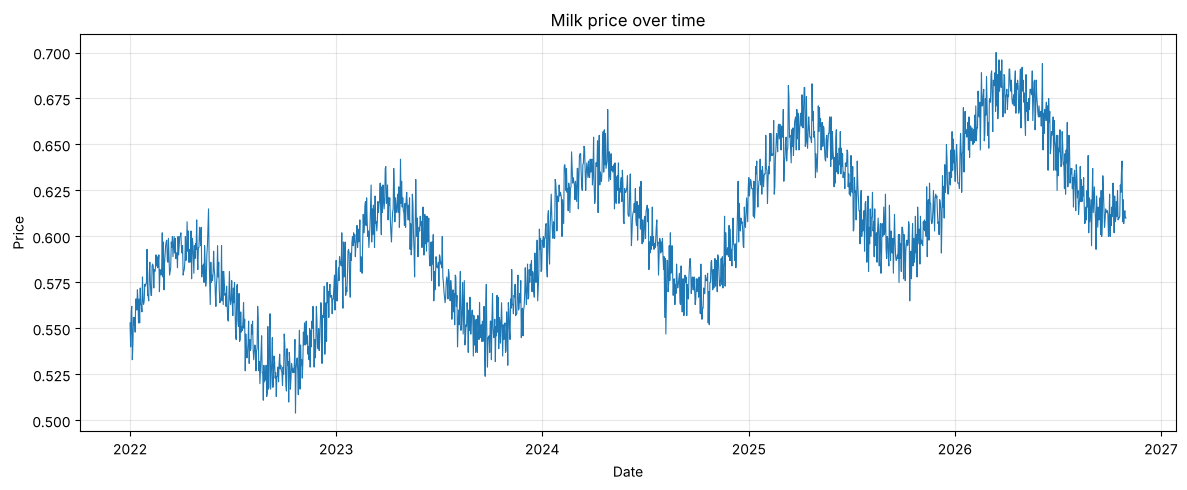

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["price"], linewidth=0.8)
plt.title("Milk price over time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Monthly average price

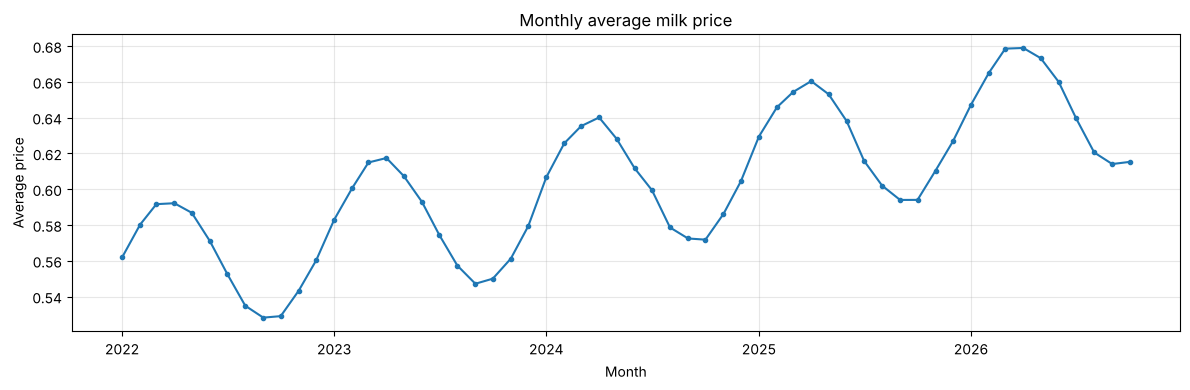

In [ ]:
monthly = df.set_index("date")["price"].resample("MS").mean()
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly.values, marker="o", markersize=3)
plt.title("Monthly average milk price")
plt.xlabel("Month")
plt.ylabel("Average price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observations

- Price shows a **gentle upward trend** over the period.
- There is a clear **yearly seasonal pattern** (visible in the monthly average).
- Daily noise is small relative to the trend; no missing values or duplicate dates.
- Next step (Task 2): build a baseline linear regression on this data.